# Parte 2 · Grafos ICEWS e análise visual de dados

In [ ]:
import csv
import json
import math
import re
import sys
import textwrap
from collections import Counter, defaultdict
from io import BytesIO
from pathlib import Path
from statistics import correlation, mean, median

import matplotlib
from IPython.display import Image, display

matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

pasta_atual = Path.cwd()
inicio = pasta_atual.resolve()
RAIZ = None

for pasta in (inicio, *inicio.parents):
    algoritmos_existem = (pasta / "src/graphs/algorithms.py").is_file()
    dataset_existe = (pasta / "data/dataset_parte2/arestas_paises.csv").is_file()

    if algoritmos_existem and dataset_existe:
        RAIZ = pasta
        break

if RAIZ is None:
    raise FileNotFoundError("Abra o notebook a partir do repositório projeto-grafos.")

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.benchmark_parte2 import (
    DATASET,
    FONTES,
    PARES,
    REPETICOES,
    SAIDA as CAMINHO_RELATORIO,
    SEED,
    executar_pipeline_parte2,
)

PROCESSADO = DATASET / "processado"
SAIDA = CAMINHO_RELATORIO.parent

## 1. Grafo e custo dos caminhos

Cada nó representa um país. A aresta de A para B guarda a intensidade média dos eventos de A para B. O Bellman-Ford usa esse peso original, que vai de −10 a +10.

A BFS procura o caminho com menos saltos. Para o Dijkstra, usamos `10 - peso` como custo: 0 é o menor atrito possível e 20 é o maior. Somamos esse mesmo custo nas duas rotas para comparar a diferença.

Uma aresta com apenas um evento é um par fraco. Na análise de robustez, tiramos essas arestas e mantemos todos os países.

## 2. Como medimos o tempo

Rodamos cada tarefa cinco vezes e guardamos a média e o desvio-padrão. Na BFS e na DFS, cada repetição passa pelas três fontes. O Dijkstra roda uma vez por origem dos cinco pares. Cada cenário do Bellman-Ford usa uma origem. A leitura do CSV e a montagem dos grafos ficam fora do cronômetro.

No teste de escalabilidade, usamos 10%, 50% e 100% dos países. A semente 42 permite repetir o sorteio. Em cada subgrafo, todos os algoritmos saem do país com mais arestas de saída. Em caso de empate, vale a ordem alfabética.

## 3. Buscas, ciclos e robustez

A BFS registra o alcance e os primeiros países encontrados. A DFS conta os tipos de aresta. No grafo completo, guardamos o ciclo negativo que o Bellman-Ford encontra, o custo desse ciclo e os eventos de cada aresta.

No recorte, as arestas seguem a ordem de atividade dos países. Um caminho só pode avançar nessa ordem, o que impede a formação de ciclos. Conferimos o resultado com Bellman-Ford e com a contagem de arestas de retorno da DFS.

Por fim, repetimos Dijkstra e Bellman-Ford sem os pares fracos e vemos quais rotas mudam e se ainda há ciclo negativo.

In [ ]:
if CAMINHO_RELATORIO.is_file():
    with CAMINHO_RELATORIO.open(encoding="utf-8") as arquivo:
        relatorio = json.load(arquivo)
else:
    relatorio = executar_pipeline_parte2(DATASET, seed=SEED, repeticoes=REPETICOES)

meta = relatorio["metadata"]

print(f"{meta['n_nos_completo']} países | {meta['n_arestas_completo']} arestas | "
      f"{meta['n_negativas_completo']} arestas negativas | {meta['n_pares_fracos']} pares fracos")

for medida in relatorio["tempo_medio"]:
    print(f"{medida['algoritmo']} · {medida['tarefa']} · "
          f"{medida['media_ms']:.3f} ± {medida['desvio_ms']:.3f} ms")

recorte = relatorio["casos_obrigatorios"]["bellman_ford_sem_ciclo"]

for fonte, caso in recorte["execucoes"].items():
    print(f"Recorte · {fonte} · {caso['alcancados']} alcançados · "
          f"{caso['dfs_arestas_retorno']} arestas de retorno")

robustez = relatorio["robustez_sem_pares_fracos"]
rotas_alteradas = 0
for rota in robustez["dijkstra_5_pares"]:
    if rota["mudou_em_relacao_ao_completo"]:
        rotas_alteradas += 1
print(
    f"Sem pares fracos · {robustez['n_arestas']} arestas · "
    f"{rotas_alteradas} rotas de Dijkstra alteradas"
)

250 países | 29381 arestas | 2940 arestas negativas | 4284 pares fracos
BFS · 3_fontes · 6.364 ± 0.502 ms
DFS · 3_fontes · 23.939 ± 2.684 ms
DIJKSTRA · 5_pares · 58.646 ± 2.408 ms
BELLMAN_FORD · completo_com_ciclo · 1078.337 ± 101.254 ms
BELLMAN_FORD · recorte_sem_ciclo · 349.985 ± 18.850 ms
Recorte · United States · 250 alcançados · 0 arestas de retorno
Recorte · Brazil · 214 alcançados · 0 arestas de retorno
Sem pares fracos · 25097 arestas · 2 rotas de Dijkstra alteradas


## 4. Gráficos do benchmark

In [6]:
AZUL = "#23689b"
VERMELHO = "#b73c36"
VERDE = "#23857e"
CINZA = "#59636e"
NEUTRO = "#414a54"

PAISES = {
    "Lebanon": "Líbano",
    "Saudi Arabia": "Arábia Saudita",
    "Yemen": "Iêmen",
    "Russian Federation": "Rússia",
    "Ukraine": "Ucrânia",
    "Brazil": "Brasil",
    "Bhutan": "Butão",
    "United States": "Estados Unidos",
    "Iraq": "Iraque",
    "Occupied Palestinian Territory": "Território Palestino Ocupado",
    "Guyana": "Guiana",
}
LOCAIS = {
    "domestico": "Doméstico",
    "domestico_no_exterior": "Doméstico no exterior",
    "sem_pais_ator": "Sem país de um ator",
    "bilateral_no_destino": "Bilateral no destino",
    "bilateral_terceiro_pais": "Bilateral em terceiro país",
    "bilateral_na_origem": "Bilateral na origem",
}
SETORES = {
    "Executive Office": "Gabinete executivo",
    "Center Right": "Centro-direita",
    "Cabinet": "Gabinete ministerial",
    "International Government Organization": "Organização intergovernamental",
    "Foreign Ministry": "Ministério das Relações Exteriores",
    "Dissident": "Dissidência",
    "Police": "Polícia",
    "Military": "Forças armadas",
    "General Population / Civilian / Social": "População geral / Civil / Social",
    "Social": "Social",
    "Government": "Governo",
    "Executive": "Executivo",
    "Elite": "Elite",
    "Head of Government": "Chefia de governo",
    "Media": "Imprensa",
    "Political Opposition": "Oposição política",
    "Parties": "Partidos",
    "(National) Major Party": "Grande partido nacional",
    "Ideological": "Ideológico",
    "Legislative / Parliamentary": "Legislativo / Parlamentar",
}


figuras = {}


def mostrar(fig, nome):
    figuras[nome] = fig
    with BytesIO() as previa:
        fig.savefig(
            previa,
            format="png",
            dpi=90,
            bbox_inches="tight",
            facecolor="white",
        )
        imagem = Image(data=previa.getvalue(), width=900)
        display(imagem)
    plt.close(fig)


def ler_csv(caminho):
    with caminho.open(encoding="utf-8", newline="") as arquivo:
        leitor = csv.DictReader(arquivo)
        linhas = list(leitor)

    return linhas


def rotulo_numero(valor, decimais=0):
    if round(valor, decimais) == 0:
        valor = 0
    numero = f"{valor:,.{decimais}f}"
    separadores = str.maketrans(",.", ".,")
    return numero.translate(separadores)


def nome_par(origem, destino, separador=" "):
    nome_origem = PAISES.get(origem, origem)
    nome_destino = PAISES.get(destino, destino)
    return f"{nome_origem} →{separador}{nome_destino}"


def formatar_eixo_decimal(ax, decimais=1):
    ax.yaxis.set_major_formatter(
        FuncFormatter(lambda valor, _pos: rotulo_numero(valor, decimais))
    )


def grade(ax, eixo="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=eixo, color="#d5dce1", linewidth=0.7, alpha=0.8)

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "figure.titlesize": 17,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

### Tempo médio por tarefa

As barras mostram a média e as linhas no topo mostram o desvio-padrão. O painel de Bellman-Ford usa segundos. O painel de BFS, DFS e Dijkstra usa milissegundos.

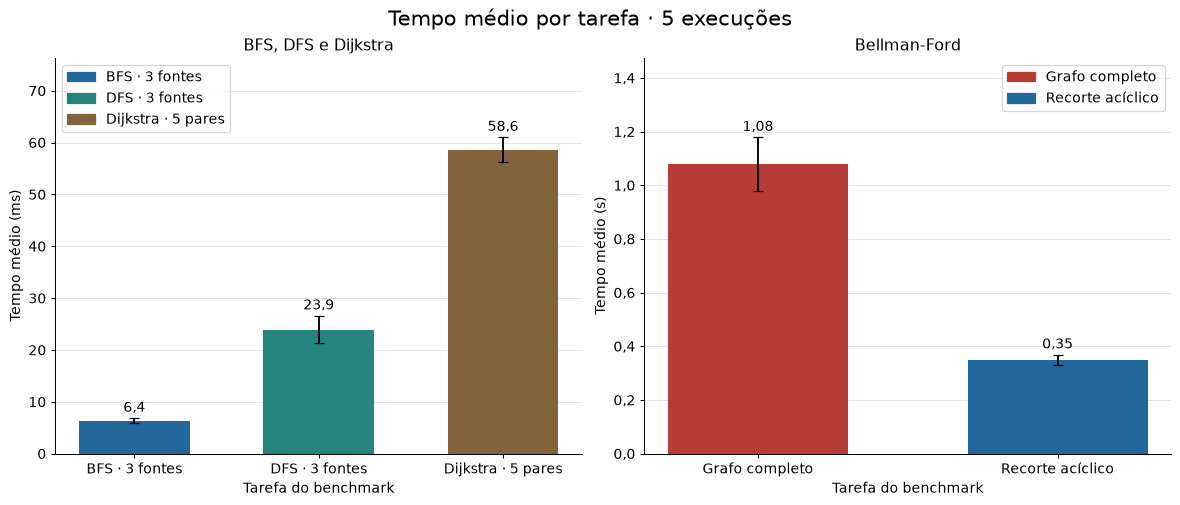

In [ ]:
def tempo_medio(relatorio):
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
    fig.suptitle(f"Tempo médio por tarefa · {relatorio['metadata']['repeticoes']} execuções")
    dados = relatorio["tempo_medio"]
    paineis = [
        {
            "eixo": eixos[0],
            "tarefas": dados[:3],
            "rotulos": ("BFS · 3 fontes", "DFS · 3 fontes", "Dijkstra · 5 pares"),
            "cores": (AZUL, VERDE, "#82633c"),
            "fator": 1,
            "unidade": "ms",
            "decimais_rotulo": 1,
            "decimais_eixo": 0,
            "titulo": "BFS, DFS e Dijkstra",
        },
        {
            "eixo": eixos[1],
            "tarefas": dados[3:],
            "rotulos": ("Grafo completo", "Recorte acíclico"),
            "cores": (VERMELHO, AZUL),
            "fator": 1000,
            "unidade": "s",
            "decimais_rotulo": 2,
            "decimais_eixo": 1,
            "titulo": "Bellman-Ford",
        },
    ]

    for painel in paineis:
        ax = painel["eixo"]
        itens = painel["tarefas"]
        fator = painel["fator"]
        unidade = painel["unidade"]
        nomes = painel["rotulos"]
        paleta = painel["cores"]
        valores = []
        desvios = []
        for item in itens:
            valores.append(item["media_ms"] / fator)
            desvios.append(item["desvio_ms"] / fator)

        grade(ax)
        barras = ax.bar(nomes, valores, yerr=desvios, color=paleta, capsize=4, width=0.6)
        maior_altura = 0
        for barra, valor, desvio in zip(barras, valores, desvios):
            centro = barra.get_x() + barra.get_width() / 2
            altura = valor + desvio
            maior_altura = max(maior_altura, altura)
            ax.annotate(
                rotulo_numero(valor, painel["decimais_rotulo"]),
                (centro, altura),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
            )

        ax.set(
            ylim=(0, maior_altura * 1.25),
            xlabel="Tarefa do benchmark",
            ylabel=f"Tempo médio ({unidade})",
            title=painel["titulo"],
        )
        formatar_eixo_decimal(ax, painel["decimais_eixo"])

        legenda = []
        for cor, nome in zip(paleta, nomes):
            legenda.append(Patch(color=cor, label=nome))
        ax.legend(handles=legenda)
    mostrar(fig, "alg_01_tempo_medio")


tempo_medio(relatorio)

### Tempo por tamanho do subgrafo

O eixo horizontal mostra quantos países e arestas ficaram em cada amostra. As linhas ajudam a comparar como o tempo varia de um tamanho para outro.

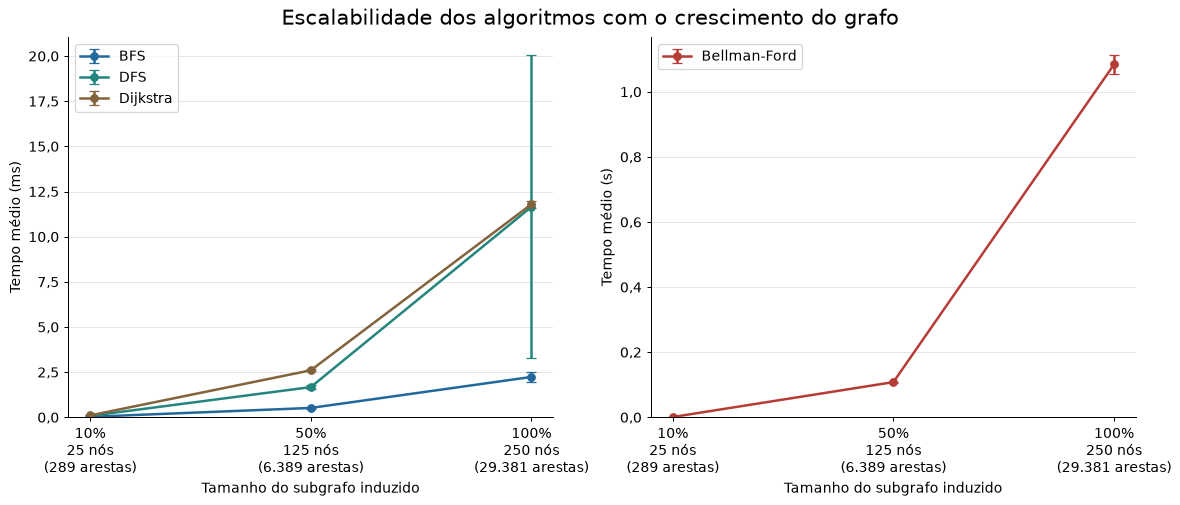

In [ ]:
def escalabilidade(relatorio):
    grupos = defaultdict(list)
    for item in relatorio["escalabilidade"]:
        grupos[item["algoritmo"]].append(item)
    fig, eixos = plt.subplots(1, 2, figsize=(13, 5.5), layout="constrained")
    fig.suptitle("Escalabilidade dos algoritmos com o crescimento do grafo")
    pontos = []
    for item in grupos["BFS"]:
        arestas = rotulo_numero(item["n_arestas"])
        pontos.append(f'{item["fracao"]:.0%}\n{item["n_nos"]} nós\n({arestas} arestas)')

    series = (
        ("BFS", "BFS", AZUL),
        ("DFS", "DFS", VERDE),
        ("DIJKSTRA", "Dijkstra", "#82633c"),
        ("BELLMAN_FORD", "Bellman-Ford", VERMELHO),
    )
    for chave, nome, cor in series:
        if chave == "BELLMAN_FORD":
            ax = eixos[1]
            fator = 1000
        else:
            ax = eixos[0]
            fator = 1

        medias = []
        desvios = []
        for item in grupos[chave]:
            medias.append(item["media_ms"] / fator)
            desvios.append(item["desvio_ms"] / fator)

        ax.errorbar(
            pontos,
            medias,
            yerr=desvios,
            marker="o",
            capsize=4,
            linewidth=2,
            color=cor,
            label=nome,
        )
    for ax, unidade in zip(eixos, ("ms", "s")):
        ax.set(xlabel="Tamanho do subgrafo induzido", ylabel=f"Tempo médio ({unidade})",
               ylim=(0, None))
        formatar_eixo_decimal(ax, 1)
        ax.legend()
        grade(ax)
    mostrar(fig, "alg_02_escalabilidade")


escalabilidade(relatorio)

### Saltos e atrito nas cinco rotas

Um painel mostra o número de saltos e o outro mostra a soma do atrito. As barras hachuradas indicam as rotas do Dijkstra que passam por um par fraco.

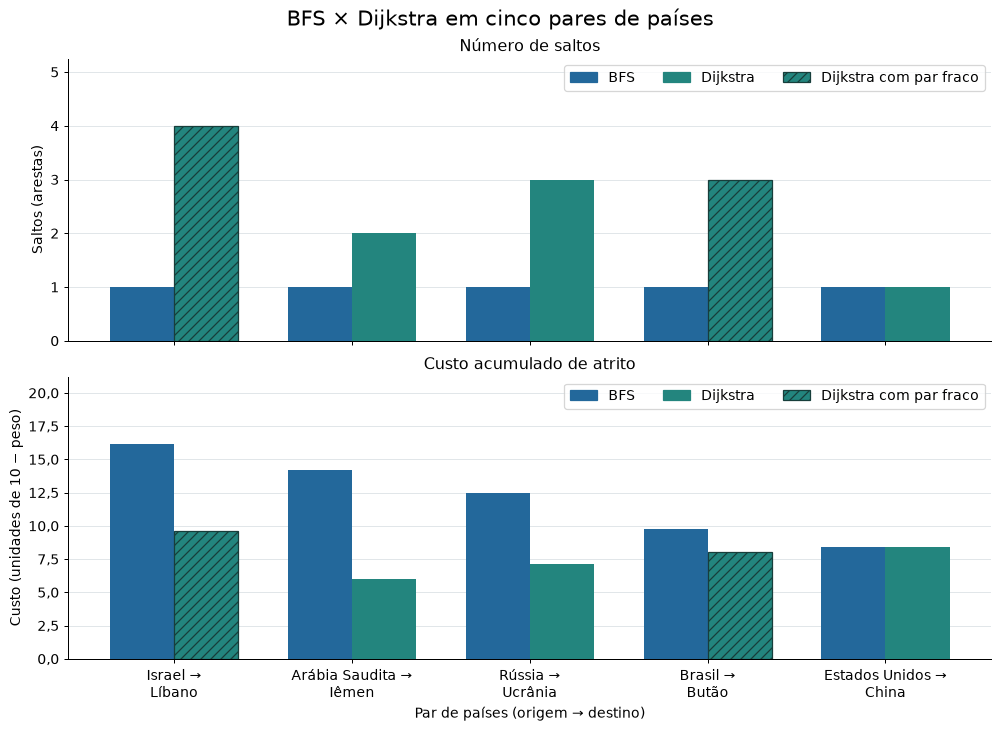

In [ ]:
def comparar_rotas(relatorio):
    casos = relatorio["bfs_vs_dijkstra_5_pares"]
    fig, eixos = plt.subplots(2, 1, figsize=(11, 8), sharex=True, layout="constrained")
    fig.suptitle("BFS × Dijkstra em cinco pares de países")
    posicoes = range(len(casos))
    paineis = (
        (eixos[0], "saltos", "Número de saltos", "Saltos (arestas)"),
        (
            eixos[1],
            "custo_transformado",
            "Custo acumulado de atrito",
            "Custo (unidades de 10 − peso)",
        ),
    )

    for ax, campo, titulo, eixo in paineis:
        for algoritmo, nome, cor, deslocamento in (
            ("bfs", "BFS", AZUL, -0.18),
            ("dijkstra", "Dijkstra", VERDE, 0.18),
        ):
            posicoes_barras = []
            valores = []

            for posicao, caso in zip(posicoes, casos):
                posicoes_barras.append(posicao + deslocamento)
                valores.append(caso[algoritmo][campo])

            barras = ax.bar(
                posicoes_barras,
                valores,
                width=0.36,
                color=cor,
                label=nome,
            )
            for barra, caso in zip(barras, casos):
                if algoritmo == "dijkstra" and caso[algoritmo]["usa_par_fraco"]:
                    barra.set(hatch="///", edgecolor="#173e3b")
        legenda = [
            Patch(color=AZUL, label="BFS"),
            Patch(color=VERDE, label="Dijkstra"),
            Patch(
                facecolor=VERDE,
                edgecolor="#173e3b",
                hatch="///",
                label="Dijkstra com par fraco",
            ),
        ]
        ax.legend(handles=legenda, ncols=3)
        limite_inferior, limite_superior = ax.get_ylim()
        ax.set(
            title=titulo,
            ylabel=eixo,
            ylim=(0, limite_superior * 1.25),
        )
        if campo == "custo_transformado":
            formatar_eixo_decimal(ax, 1)
        grade(ax)

    rotulos = []
    for caso in casos:
        rotulos.append(nome_par(caso["origem"], caso["destino"], "\n"))
    eixos[-1].set_xticks(list(posicoes), rotulos)
    eixos[-1].set_xlabel("Par de países (origem → destino)")
    mostrar(fig, "alg_03_bfs_vs_dijkstra")


comparar_rotas(relatorio)

## 5. AVD exploratória da rede

In [ ]:
arestas = ler_csv(DATASET / "arestas_paises.csv")
for item in arestas:
    item["peso"] = float(item["peso"])
    item["n_eventos"] = int(item["n_eventos"])
    item["anos_com_eventos"] = int(item["anos_com_eventos"])

### Graus de saída e de entrada

Cada ponto é um país. A diagonal indica graus iguais. O coeficiente de Pearson resume quanto os dois graus variam juntos.

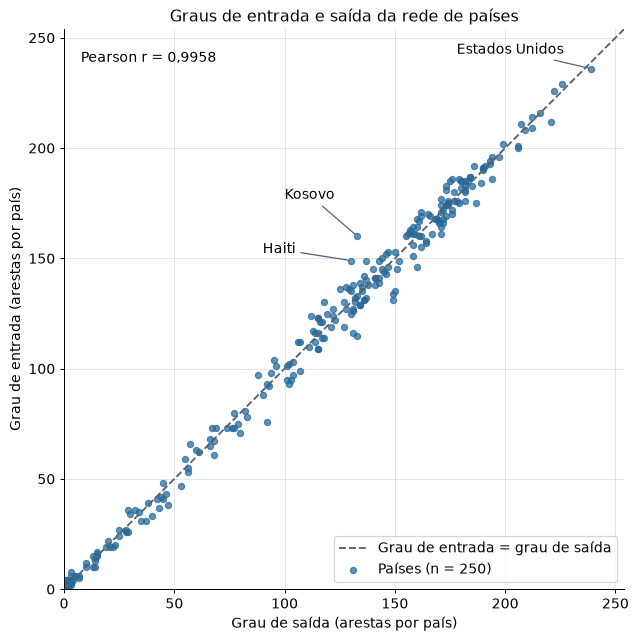

In [ ]:
def graus(arestas):
    saida = Counter()
    entrada = Counter()
    for aresta in arestas:
        saida[aresta["origem"]] += 1
        entrada[aresta["destino"]] += 1

    paises = sorted(saida.keys() | entrada.keys())
    graus_saida = []
    graus_entrada = []
    for pais in paises:
        graus_saida.append(saida[pais])
        graus_entrada.append(entrada[pais])
    fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
    maior_saida = max(graus_saida)
    maior_entrada = max(graus_entrada)
    limite = max(maior_saida, maior_entrada) + 15
    ax.plot([0, limite], [0, limite], "--", color=CINZA, label="Grau de entrada = grau de saída")
    ax.scatter(
        graus_saida,
        graus_entrada,
        s=24,
        alpha=0.72,
        color=AZUL,
        label=f"Países (n = {len(paises)})",
    )

    rotulos = (
        ("United States", (-22, 12)),
        ("Kosovo", (-18, 30)),
        ("Haiti", (-44, 6)),
    )
    for pais, deslocamento in rotulos:
        ax.annotate(
            PAISES.get(pais, pais),
            (saida[pais], entrada[pais]),
            xytext=deslocamento,
            textcoords="offset points",
            ha="right",
            arrowprops={"arrowstyle": "-", "color": CINZA},
        )

    pearson = correlation(graus_saida, graus_entrada)
    ax.text(
        0.03,
        0.96,
        f"Pearson r = {rotulo_numero(pearson, 4)}",
        transform=ax.transAxes,
        va="top",
    )
    ax.set(xlabel="Grau de saída (arestas por país)", ylabel="Grau de entrada (arestas por país)",
           xlim=(0, limite), ylim=(0, limite), title="Graus de entrada e saída da rede de países")
    ax.set_aspect("equal")
    ax.legend(loc="lower right")
    grade(ax, "both")
    mostrar(fig, "avd_exp1_graus")


graus(arestas)

### Distribuição dos pesos

O histograma agrupa os pesos em faixas de 0,5. As cores separam os pesos negativos dos demais e a linha marca a mediana.

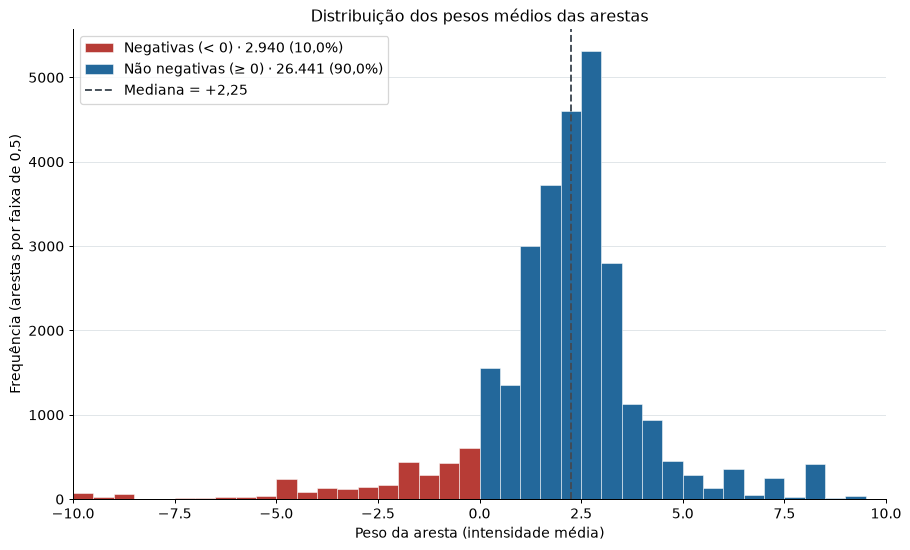

In [ ]:
def histograma_pesos(arestas):
    pesos = []
    negativas = []
    demais = []

    for aresta in arestas:
        peso = aresta["peso"]
        pesos.append(peso)

        if peso < 0:
            negativas.append(peso)
        else:
            demais.append(peso)

    limites_negativos = []

    for passo in range(-20, 1):
        limites_negativos.append(passo / 2)

    limites_nao_negativos = []

    for passo in range(21):
        limites_nao_negativos.append(passo / 2)

    mediana = median(pesos)
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

    for grupo, bins, cor, nome in (
        (negativas, limites_negativos, VERMELHO, "Negativas (< 0)"),
        (demais, limites_nao_negativos, AZUL, "Não negativas (≥ 0)"),
    ):
        quantidade = rotulo_numero(len(grupo))
        percentual = rotulo_numero(100 * len(grupo) / len(pesos), 1)
        legenda = f"{nome} · {quantidade} ({percentual}%)"
        ax.hist(grupo, bins=bins, color=cor, edgecolor="white", linewidth=0.4, label=legenda)

    rotulo_mediana = rotulo_numero(mediana, 2)

    ax.axvline(
        mediana,
        color=NEUTRO,
        linestyle="--",
        label=f"Mediana = +{rotulo_mediana}",
    )

    ax.set(
        title="Distribuição dos pesos médios das arestas",
        xlim=(-10, 10),
        xlabel="Peso da aresta (intensidade média)",
        ylabel="Frequência (arestas por faixa de 0,5)",
    )

    ax.legend(loc="upper left")
    
    grade(ax)
    mostrar(fig, "avd_exp2_histograma_peso")


histograma_pesos(arestas)

### Volume de eventos e peso médio

Usamos escala logarítmica no volume para mostrar arestas com poucos e muitos eventos no mesmo eixo. A cor indica em quantos anos o par teve eventos.

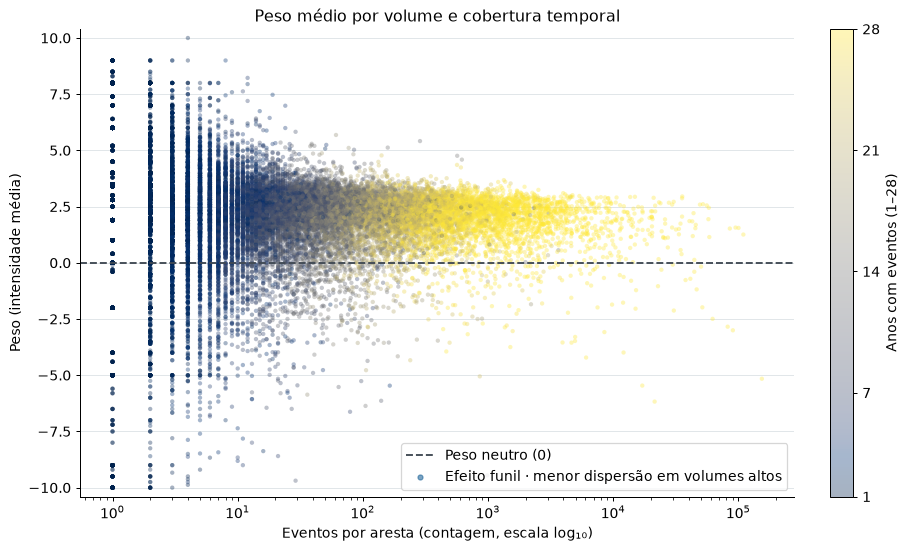

In [ ]:
def eventos_peso(arestas):
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    volumes = []
    pesos = []
    cobertura = []

    for aresta in arestas:
        volumes.append(aresta["n_eventos"])
        pesos.append(aresta["peso"])
        cobertura.append(aresta["anos_com_eventos"])

    pontos = ax.scatter(
        volumes,
        pesos,
        c=cobertura,
        cmap="cividis",
        vmin=1,
        vmax=28,
        s=12,
        alpha=0.35,
        linewidths=0,
    )
    fig.colorbar(pontos, ax=ax, label="Anos com eventos (1–28)", ticks=[1, 7, 14, 21, 28])
    
    ax.axhline(0, color=NEUTRO, linestyle="--", label="Peso neutro (0)")
    ax.scatter([], [], color=AZUL, s=16, alpha=0.6,
               label="Efeito funil · menor dispersão em volumes altos")
    ax.set(
        xscale="log",
        ylim=(-10.4, 10.4),
        title="Peso médio por volume e cobertura temporal",
        xlabel="Eventos por aresta (contagem, escala log₁₀)",
        ylabel="Peso (intensidade média)",
    )
    ax.legend(loc="lower right")
    
    grade(ax)
    mostrar(fig, "avd_exp3_eventos_vs_peso")


eventos_peso(arestas)

## 6. Intensidade dos eventos

Aqui usamos os eventos brutos para comparar a intensidade por família CAMEO, setor de origem, veículo e local. Para o gráfico por ano, lemos a série do resumo anual do projeto.

Lemos os TSVs linha por linha e guardamos a contagem e a soma de cada grupo. Corrigimos os zeros que se perderam nos códigos CAMEO e pulamos os códigos sem família válida. Cada setor conta uma vez por evento. Tratamos `NULL` como campo vazio e agrupamos os veículos sem identificação em **Desconhecido**.

In [ ]:
PADRAO_ANO = re.compile(r"^(?:events|eventos)[._-]?(\d{4})", re.IGNORECASE)

CAMPOS = ("CAMEO Code", "Intensity", "Source Sectors", "Publisher",
          "Source Country", "Target Country", "Country")

FAMILIAS = (
    "Fazer declaração pública", "Fazer apelo", "Expressar intenção de cooperar",
    "Consultar", "Engajar-se em cooperação diplomática", "Engajar-se em cooperação material",
    "Fornecer ajuda", "Ceder", "Investigar", "Exigir", "Desaprovar", "Rejeitar",
    "Ameaçar", "Protestar", "Demonstrar força militar", "Reduzir relações",
    "Coagir", "Agredir", "Combater", "Usar violência em massa não convencional",
)

NOMES_FAMILIAS = {}

for numero, nome in enumerate(FAMILIAS, 1):
    codigo_familia = f"{numero:02d}"
    NOMES_FAMILIAS[codigo_familia] = nome


def normalizar_cameo(codigo):
    
    if not codigo.isascii() or not codigo.isdigit():
        return None
    
    if len(codigo) == 2:
        codigo = codigo.zfill(3)
    elif len(codigo) == 3 and codigo[0] in "23456789" and not codigo.startswith("20"):
        codigo = codigo.zfill(4)
    familia = codigo[:2]
    
    if len(codigo) in (3, 4) and familia in NOMES_FAMILIAS:
        return familia
    
    return None


def limpar_ausencia(valor):
    valor = valor.strip()
    
    if valor == "NULL":
        return ""
    
    return valor


def tipo_localizacao(origem, destino, local):
    
    if not origem or not destino:
        return "sem_pais_ator"
    
    if origem == destino:
    
        if local == origem:
            return "domestico"
    
        return "domestico_no_exterior"
    
    if local == origem:
        return "bilateral_na_origem"
    
    if local == destino:
        return "bilateral_no_destino"
    
    return "bilateral_terceiro_pais"


def acumular(grupos, chave, intensidade):
    
    if chave not in grupos:
        grupos[chave] = [0, 0.0]

    grupo = grupos[chave]
    grupo[0] += 1
    grupo[1] += intensidade


def ordem_por_frequencia(grupo):
    chave, totais = grupo
    contagem = totais[0]
    
    return -contagem, chave


def medias_por_frequencia(grupos, campo):
    ordenados = sorted(grupos.items(), key=ordem_por_frequencia)
    medias = []
    
    for chave, totais in ordenados:
        contagem, soma = totais
        media = soma / contagem
        medias.append({
            campo: chave,
            "media_intensidade": media,
        })
    
    return medias


def preparar_intensidades(pasta_raw):
    arquivos_por_ano = defaultdict(list)
    
    for arquivo in sorted(pasta_raw.glob("*.tab")):
        correspondencia = PADRAO_ANO.match(arquivo.name)
    
        if correspondencia:
            ano = int(correspondencia[1])
            arquivos_por_ano[ano].append(arquivo)

    anos = range(1995, 2023)
    faltam = []
    
    for ano in anos:
    
        if ano not in arquivos_por_ano:
            faltam.append(ano)
    
    if faltam:
        raise FileNotFoundError(f"Arquivos anuais ausentes em {pasta_raw}: {faltam}")

    cameo = {}
    setores = {}
    veiculos = {}
    locais = {}

    total = 0
    normalizados = 0
    invalidos = 0
    
    for ano in anos:
    
        for arquivo in arquivos_por_ano[ano]:
    
            with arquivo.open(encoding="utf-8-sig", newline="") as entrada:
                leitor = csv.reader(entrada, delimiter="\t")
                cabecalho = []
    
                for campo in next(leitor, []):
                    cabecalho.append(campo.strip())

                faltantes = []
    
                for campo in CAMPOS:
    
                    if campo not in cabecalho:
                        faltantes.append(campo)

                if faltantes:
                    raise ValueError(f"{arquivo.name} sem colunas obrigatórias: {faltantes}")

                indice_cameo = cabecalho.index("CAMEO Code")
                indice_intensidade = cabecalho.index("Intensity")
                indice_setores = cabecalho.index("Source Sectors")
                indice_veiculo = cabecalho.index("Publisher")
                indice_origem = cabecalho.index("Source Country")
                indice_destino = cabecalho.index("Target Country")
                indice_local = cabecalho.index("Country")

                for linha in leitor:
    
                    if not linha:
                        continue
    
                    try:
                        intensidade = float(linha[indice_intensidade])
                    except ValueError:
                        continue
    
                    if not math.isfinite(intensidade):
                        continue
    
                    total += 1

                    codigo = linha[indice_cameo].strip()
                    familia = normalizar_cameo(codigo)
    
                    if familia is None:
                        invalidos += 1
                    else:
    
                        if familia != codigo[:2]:
                            normalizados += 1
    
                        acumular(cameo, familia, intensidade)

                    rotulos = set()
    
                    for rotulo in linha[indice_setores].split(","):
                        setor = limpar_ausencia(rotulo)
    
                        if setor:
                            rotulos.add(setor)

                    if not rotulos:
                        rotulos.add("Não classificado")

                    for setor in rotulos:
                        acumular(setores, setor, intensidade)

                    veiculo = linha[indice_veiculo].strip()
    
                    if not veiculo or veiculo.lower() == "unknown":
                        veiculo = "Desconhecido"
    
                    acumular(veiculos, veiculo, intensidade)

                    origem = limpar_ausencia(linha[indice_origem])
                    destino = limpar_ausencia(linha[indice_destino])
                    local = limpar_ausencia(linha[indice_local])
    
                    contexto = tipo_localizacao(origem, destino, local)
                    acumular(locais, contexto, intensidade)

    resumo_cameo = []
    
    for familia, nome in NOMES_FAMILIAS.items():
        contagem, soma = cameo.get(familia, (0, 0.0))
        media = 0.0
    
        if contagem:
            media = soma / contagem
    
        resumo_cameo.append({
            "familia": familia,
            "nome_familia": nome,
            "media_intensidade": media,
        })
    
    dados = {
        "cameo": resumo_cameo,
        "setor": medias_por_frequencia(setores, "setor"),
        "veiculo": medias_por_frequencia(veiculos, "veiculo"),
        "localizacao": medias_por_frequencia(locais, "tipo_localizacao"),
    }
    print(f"{total:,} eventos com intensidade | {normalizados:,} códigos CAMEO normalizados | "
          f"{invalidos:,} códigos ignorados")
    return dados


intensidades = preparar_intensidades(DATASET / "raw")

20,188,517 eventos com intensidade | 1,377,818 códigos CAMEO normalizados | 27 códigos ignorados


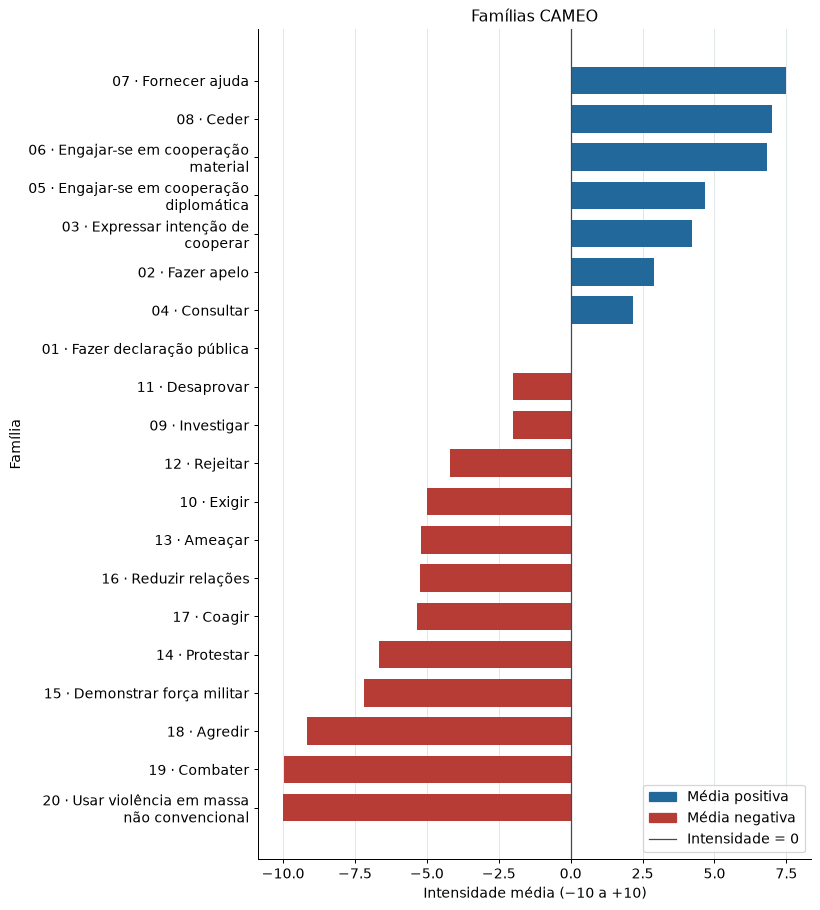

In [ ]:
def media_da_categoria(categoria):
    rotulo, media = categoria
    return media


def barras_intensidade(ax, dados, titulo, eixo, largura=30, limites=None):
    ordenado = sorted(dados, key=media_da_categoria)
    rotulos = []
    valores = []
    cores = []

    for rotulo, valor in ordenado:
        rotulo_quebrado = textwrap.fill(rotulo, largura, break_long_words=False)
        rotulos.append(rotulo_quebrado)
        valores.append(valor)

        if valor >= 0:
            cores.append(AZUL)
        else:
            cores.append(VERMELHO)

    ax.barh(range(len(valores)), valores, color=cores, height=0.72)
    ax.set_yticks(range(len(rotulos)), rotulos)
    ax.axvline(0, color=NEUTRO, linewidth=1)
    ax.set(title=titulo, xlabel="Intensidade média (−10 a +10)", ylabel=eixo, xlim=limites)
    grade(ax, "x")


def legenda_intensidade():
    return [
        Patch(color=AZUL, label="Média positiva"),
        Patch(color=VERMELHO, label="Média negativa"),
        Line2D([], [], color=NEUTRO, linewidth=1, label="Intensidade = 0"),
    ]


def series_intensidade(dados, chave, nomes):
    series = []
    for item in dados:
        categoria = item[chave]
        rotulo = nomes.get(categoria, categoria)
        media = float(item["media_intensidade"])
        series.append((rotulo, media))

    return series


cameo = []
for item in intensidades["cameo"]:
    rotulo = f'{item["familia"]} · {item["nome_familia"]}'
    media = float(item["media_intensidade"])
    cameo.append((rotulo, media))

fig, ax = plt.subplots(figsize=(9, 10), layout="constrained")
barras_intensidade(ax, cameo, "Famílias CAMEO", "Família", largura=29)
ax.legend(handles=legenda_intensidade(), loc="lower right")
mostrar(fig, "avd_exp4_cameo")

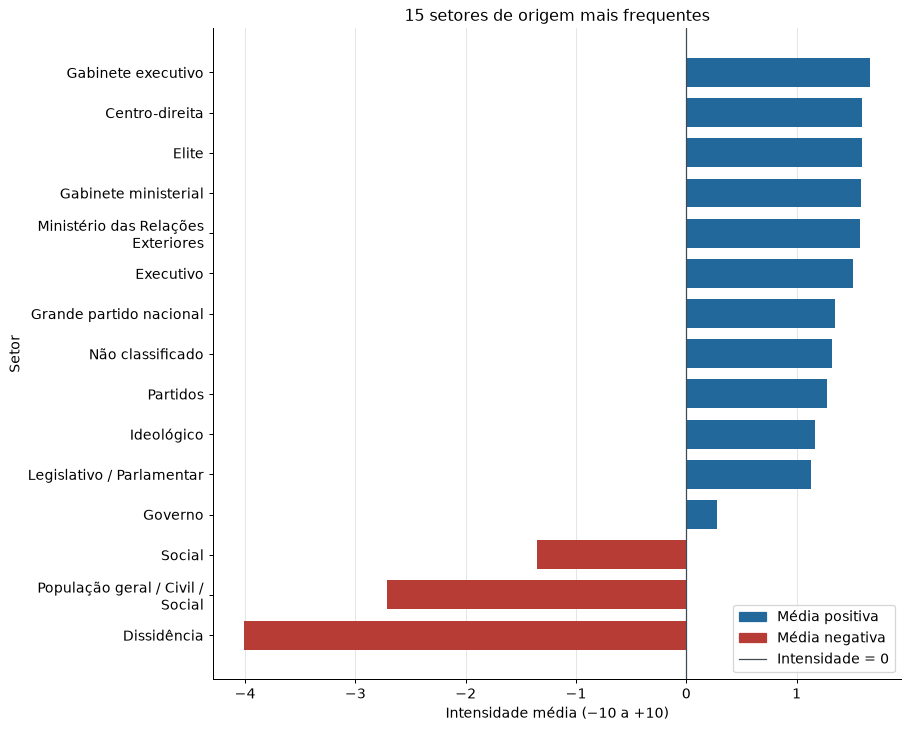

In [ ]:
setores_frequentes = intensidades["setor"][:15]
setores = series_intensidade(setores_frequentes, "setor", SETORES)

fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
barras_intensidade(ax, setores, "15 setores de origem mais frequentes", "Setor")
ax.legend(handles=legenda_intensidade(), loc="lower right")
mostrar(fig, "avd_exp4_setores")

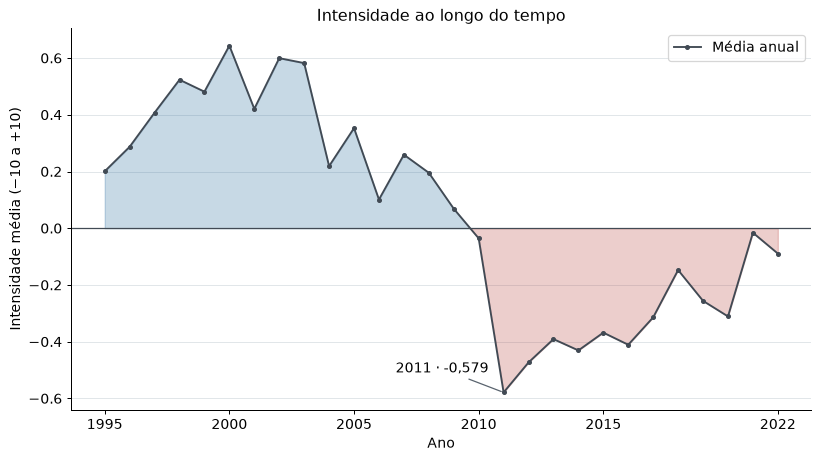

In [ ]:
resumo_anos = ler_csv(PROCESSADO / "resumo_anos.csv")
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")

anos = []
medias = []
faixa_nao_negativa = []
faixa_negativa = []
for item in resumo_anos:
    ano = int(item["ano"])
    media = float(item["intensidade_media"])
    anos.append(ano)
    medias.append(media)
    faixa_nao_negativa.append(media >= 0)
    faixa_negativa.append(media < 0)

ax.plot(anos, medias, marker="o", markersize=3, color=NEUTRO, label="Média anual")
ax.fill_between(
    anos, 0, medias, where=faixa_nao_negativa, interpolate=True, alpha=0.25, color=AZUL
)
ax.fill_between(
    anos, 0, medias, where=faixa_negativa, interpolate=True, alpha=0.25, color=VERMELHO
)
ax.axhline(0, color=NEUTRO, linewidth=1)

menor_media = min(medias)
indice_menor_media = medias.index(menor_media)
ano_da_menor_media = anos[indice_menor_media]
rotulo_menor_media = f"{ano_da_menor_media} · {rotulo_numero(menor_media, 3)}"
ax.annotate(
    rotulo_menor_media,
    (ano_da_menor_media, menor_media),
    xytext=(-12, 16),
    textcoords="offset points",
    ha="right",
    arrowprops={"arrowstyle": "-", "color": CINZA},
)
ax.set(
    title="Intensidade ao longo do tempo",
    xlabel="Ano",
    ylabel="Intensidade média (−10 a +10)",
)
ax.set_xticks([1995, 2000, 2005, 2010, 2015, 2022])
ax.legend(loc="upper right")
grade(ax)
mostrar(fig, "avd_exp4_ano")

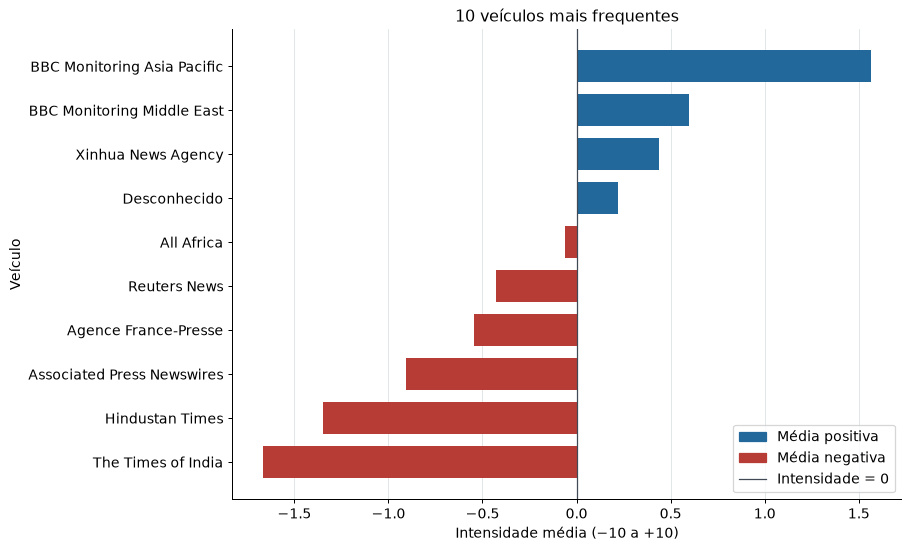

In [ ]:
veiculos_frequentes = intensidades["veiculo"][:10]
veiculos = series_intensidade(veiculos_frequentes, "veiculo", {})

fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
barras_intensidade(ax, veiculos, "10 veículos mais frequentes", "Veículo")
ax.legend(handles=legenda_intensidade(), loc="lower right")
mostrar(fig, "avd_exp4_veiculos")

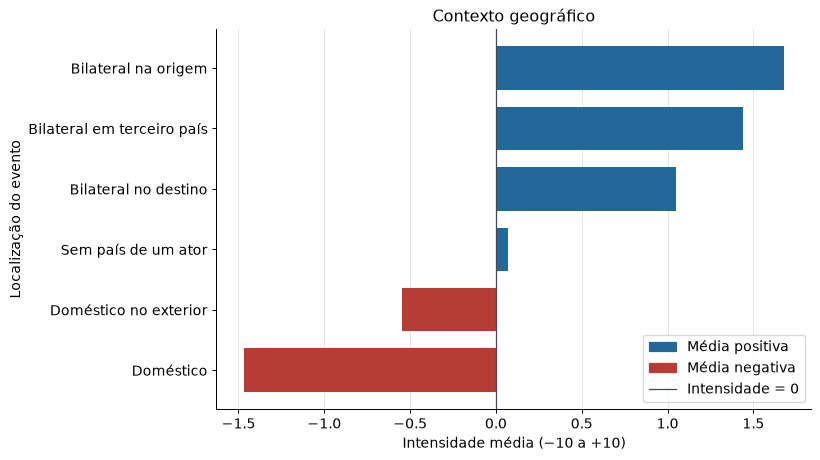

In [ ]:
locais = series_intensidade(intensidades["localizacao"], "tipo_localizacao", LOCAIS)

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
barras_intensidade(ax, locais, "Contexto geográfico", "Localização do evento")
ax.legend(handles=legenda_intensidade(), loc="lower right")
mostrar(fig, "avd_exp4_localizacao")

## 7. Dados faltantes

O mapa de calor compara a ausência de dados em dez campos. Cada célula mostra a média das correlações anuais de Pearson. Anos em que um dos campos não varia ficam fora da média daquele par. A diagonal vale 1 e as cores usam a mesma escala de −1 a +1.

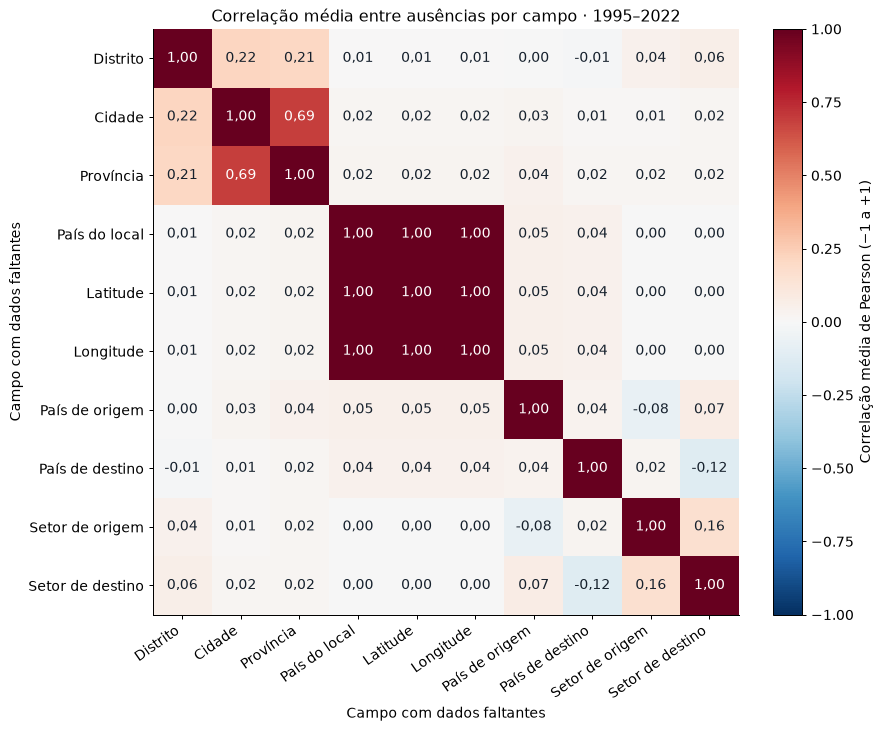

In [11]:
def heatmap_ausencias(dados):
    colunas = {
        "District": "Distrito",
        "City": "Cidade",
        "Province": "Província",
        "Country": "País do local",
        "Latitude": "Latitude",
        "Longitude": "Longitude",
        "Source Country": "País de origem",
        "Target Country": "País de destino",
        "Source Sectors": "Setor de origem",
        "Target Sectors": "Setor de destino",
    }
    pares = defaultdict(list)
    for item in dados:
        coluna_a = item["coluna_a"]
        coluna_b = item["coluna_b"]
        correlacao = item["correlacao"]
        if coluna_a in colunas and coluna_b in colunas and correlacao:
            pares[coluna_a, coluna_b].append(float(correlacao))

    matriz = []
    for coluna_a in colunas:
        linha = []
        for coluna_b in colunas:
            correlacoes = pares.get((coluna_a, coluna_b), [])
            if coluna_a == coluna_b:
                valor = 1.0
            elif correlacoes:
                valor = mean(correlacoes)
            else:
                valor = float("nan")
            linha.append(valor)
        matriz.append(linha)
    fig, ax = plt.subplots(figsize=(10, 8), layout="constrained")
    imagem = ax.imshow(matriz, cmap="RdBu_r", vmin=-1, vmax=1)
    fig.colorbar(imagem, ax=ax, label="Correlação média de Pearson (−1 a +1)")
    ax.set_xticks(range(len(colunas)), colunas.values(), rotation=35, ha="right")
    ax.set_yticks(range(len(colunas)), colunas.values())
    for i, linha in enumerate(matriz):
        for j, valor in enumerate(linha):
            rotulo = "—"
            if math.isfinite(valor):
                rotulo = rotulo_numero(valor, 2)

            cor = "#16212d"
            if abs(valor) >= 0.65:
                cor = "white"

            ax.text(j, i, rotulo, ha="center", va="center", color=cor)
    ax.set(title="Correlação média entre ausências por campo · 1995–2022",
           xlabel="Campo com dados faltantes", ylabel="Campo com dados faltantes")
    mostrar(fig, "avd_apoio_heatmap_ausencias")


correlacao_ausencias = ler_csv(PROCESSADO / "correlacao_nulos_por_ano.csv")
heatmap_ausencias(correlacao_ausencias)

## 8. AVD explanatória

### Pares de baixo volume e casos de hostilidade

A faixa mostra as arestas de um único evento. Os pontos vermelhos destacam pares com pelo menos mil eventos e peso abaixo de −2. A Guiana e Curaçao aparecem no ciclo encontrado pelo Bellman-Ford.

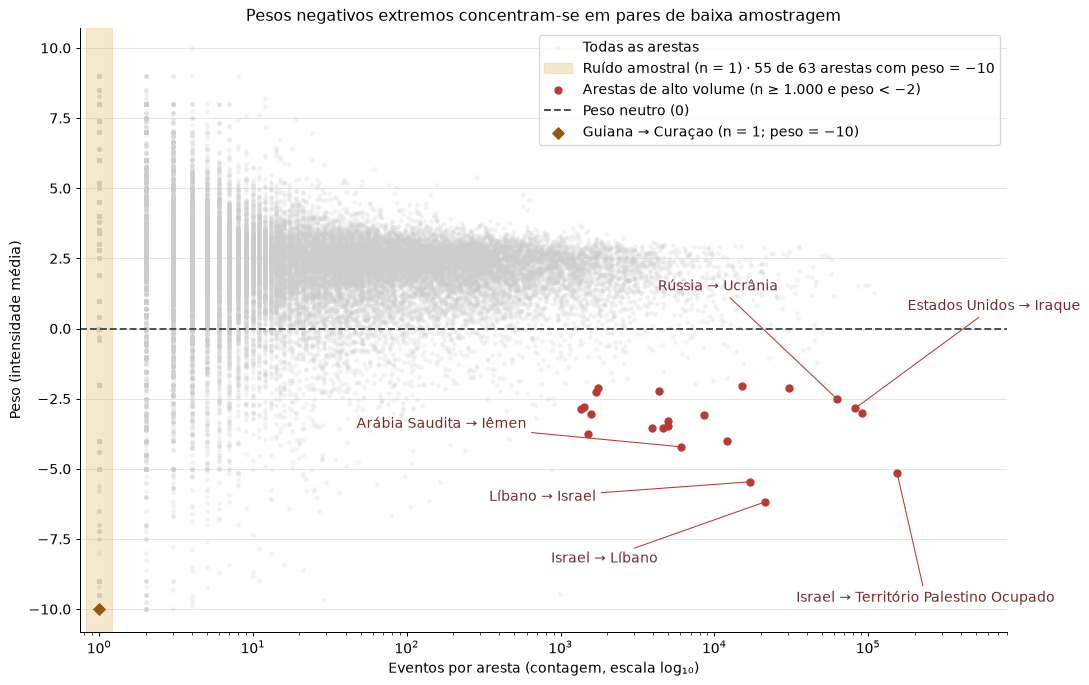

In [ ]:
def nucleos(arestas):
    volumes = []
    pesos = []
    volumes_estruturais = []
    pesos_estruturais = []
    n_extremos = 0
    n_fracas = 0
    pares = {}

    for aresta in arestas:
        volume = aresta["n_eventos"]
        peso = aresta["peso"]
        volumes.append(volume)
        pesos.append(peso)

        par = (aresta["origem"], aresta["destino"])
        pares[par] = aresta

        if peso == -10:
            n_extremos += 1
            if volume == 1:
                n_fracas += 1

        if volume >= 1000 and peso < -2:
            volumes_estruturais.append(volume)
            pesos_estruturais.append(peso)

    fig, ax = plt.subplots(figsize=(12, 7.5), layout="constrained")
    ax.scatter(
        volumes,
        pesos,
        color="#cccccc",
        alpha=0.25,
        s=14,
        linewidths=0,
        label="Todas as arestas",
    )
    ax.axvspan(
        0.82,
        1.21,
        color="#e5be75",
        alpha=0.35,
        label=f"Ruído amostral (n = 1) · {n_fracas} de {n_extremos} arestas com peso = −10",
    )
    ax.scatter(
        volumes_estruturais,
        pesos_estruturais,
        color=VERMELHO,
        s=32,
        label="Arestas de alto volume (n ≥ 1.000 e peso < −2)",
    )
    ax.axhline(0, color=NEUTRO, linestyle="--", label="Peso neutro (0)")
    atipico = pares["Guyana", "Curaçao"]
    ax.scatter(atipico["n_eventos"], atipico["peso"], color="#92580c", marker="D", s=42, zorder=4,
               label="Guiana → Curaçao (n = 1; peso = −10)")
    rotulos = (
        ("Saudi Arabia", "Yemen", (600, -3.4), "right"),
        ("Lebanon", "Israel", (1700, -6.0), "right"),
        ("Israel", "Lebanon", (4300, -8.2), "right"),
        ("Israel", "Occupied Palestinian Territory", (34000, -9.6), "left"),
        ("Russian Federation", "Ukraine", (26000, 1.5), "right"),
        ("United States", "Iraq", (180000, 0.8), "left"),
    )
    for origem, destino, texto, alinhamento in rotulos:
        item = pares[origem, destino]
        ax.annotate(nome_par(origem, destino), (item["n_eventos"], item["peso"]), xytext=texto,
                    ha=alinhamento, va="center", color="#762b29",
                    arrowprops={"arrowstyle": "-", "color": VERMELHO, "linewidth": 0.85})
    ax.set(
        title="Pesos negativos extremos concentram-se em pares de baixa amostragem",
        xscale="log",
        xlim=(0.75, 800000),
        ylim=(-10.8, 10.7),
        xlabel="Eventos por aresta (contagem, escala log₁₀)",
        ylabel="Peso (intensidade média)",
    )
    ax.legend(loc="upper right")
    grade(ax)
    mostrar(fig, "avd_explanatorio1_nucleos")


nucleos(arestas)

### Intensidade por contexto e setor

Os dois painéis usam a mesma escala para comparar as médias em torno de zero. Mostramos os seis contextos geográficos e os dez setores escolhidos no roteiro. Polícia, organização intergovernamental e forças armadas ficaram nas posições 16 a 18 por frequência.

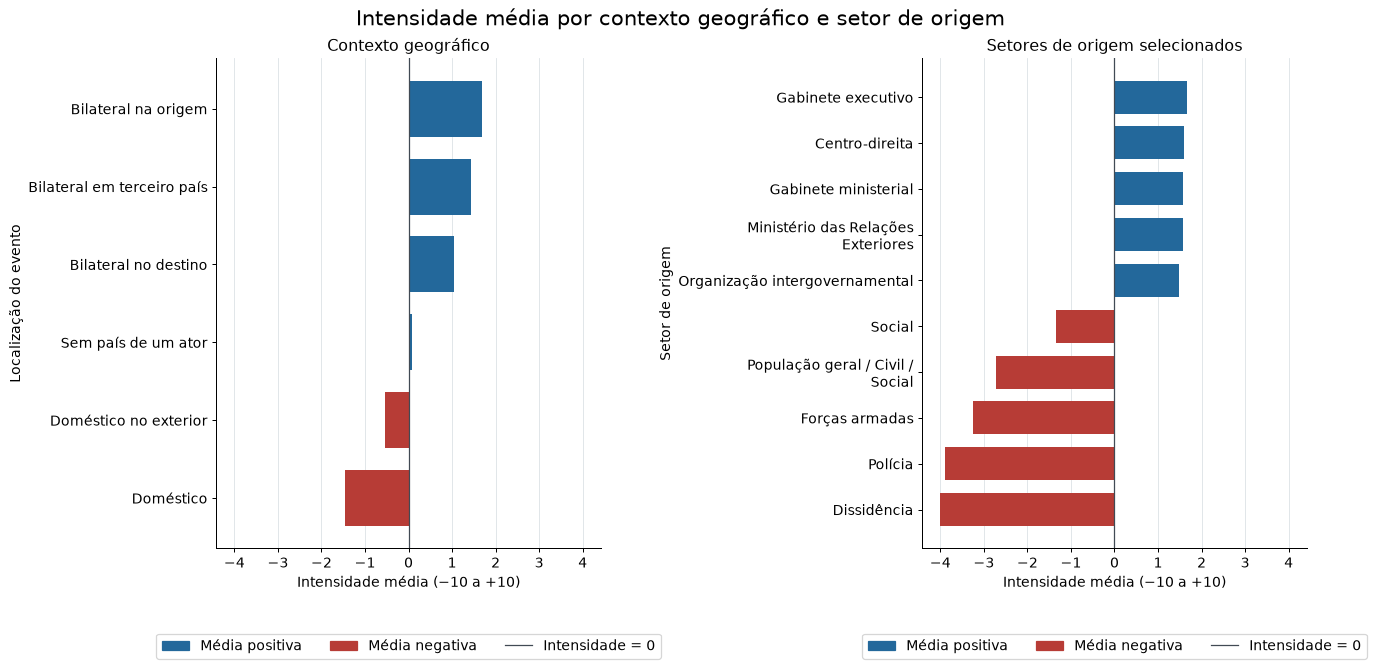

In [ ]:
def domestico_setor(intensidades):
    locais = series_intensidade(intensidades["localizacao"], "tipo_localizacao", LOCAIS)
    selecionados = {
        "Executive Office",
        "Center Right",
        "Cabinet",
        "International Government Organization",
        "Foreign Ministry",
        "Dissident",
        "Police",
        "Military",
        "General Population / Civilian / Social",
        "Social",
    }
    dados_setores = []
    for item in intensidades["setor"]:
        if item["setor"] in selecionados:
            dados_setores.append(item)

    setores = series_intensidade(dados_setores, "setor", SETORES)

    maior_magnitude = 0
    for rotulo, media in locais + setores:
        maior_magnitude = max(maior_magnitude, abs(media))
    amplitude = maior_magnitude * 1.1
    fig, eixos = plt.subplots(1, 2, figsize=(15, 7.3), layout="constrained", sharex=True)
    fig.suptitle("Intensidade média por contexto geográfico e setor de origem")
    limites = (-amplitude, amplitude)
    barras_intensidade(
        eixos[0], locais, "Contexto geográfico", "Localização do evento", limites=limites
    )
    barras_intensidade(
        eixos[1], setores, "Setores de origem selecionados", "Setor de origem", limites=limites
    )

    for ax in eixos:
        ax.legend(
            handles=legenda_intensidade(),
            loc="lower center",
            bbox_to_anchor=(0.5, -0.24),
            ncols=3,
        )
    mostrar(fig, "avd_explanatorio2_domestico_setor")


domestico_setor(intensidades)

## 9. Exportar o benchmark e os gráficos

Depois de rodar as células acima, execute esta para gravar o JSON e os 14 gráficos a 300 DPI em `out/parte2/`. Rodar de novo atualiza os mesmos arquivos.

In [ ]:
if len(figuras) != 14:
    raise RuntimeError("Execute todas as células de gráficos antes da exportação.")

SAIDA.mkdir(parents=True, exist_ok=True)
if not CAMINHO_RELATORIO.is_file():
    with CAMINHO_RELATORIO.open("w", encoding="utf-8") as arquivo:
        json.dump(relatorio, arquivo, ensure_ascii=False, indent=2, allow_nan=False)
        arquivo.write("\n")

for nome, figura in figuras.items():
    caminho_png = SAIDA / f"{nome}.png"
    figura.savefig(
        caminho_png,
        dpi=300,
        bbox_inches="tight",
        facecolor="white",
    )

print(f"Relatório conferido e {len(figuras)} PNGs exportados para {SAIDA.relative_to(RAIZ)}.")